<a href="https://colab.research.google.com/github/rachakondasaivarshini/GAN-PROGRAMS/blob/main/GAN_EXP10_PRELAB.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

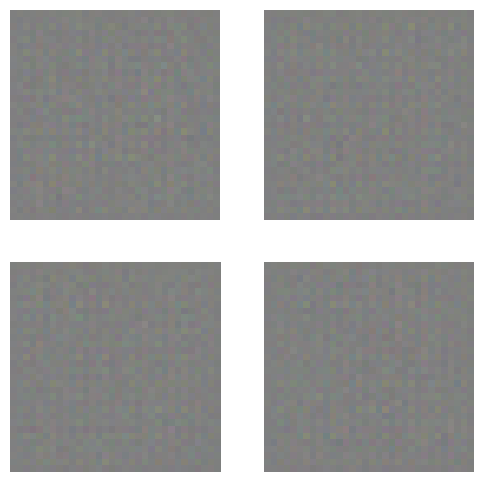

Generator loss function: <function generator_loss at 0x7dfc084f4400>
Discriminator loss function: <function discriminator_loss at 0x7dfc08487420>
Generated image shape: (4, 32, 32, 3)


In [1]:
import tensorflow as tf
from tensorflow.keras import layers
import matplotlib.pyplot as plt

# Generator
generator = tf.keras.Sequential([
    layers.Input(shape=(100,)),
    layers.Dense(8*8*128),
    layers.Reshape((8, 8, 128)),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Conv2DTranspose(
        64, 4, strides=2, padding='same'),
    layers.BatchNormalization(),
    layers.ReLU(),
    layers.Conv2DTranspose(
        3, 4, strides=2, padding='same',
        activation='tanh')
])

# Discriminator
discriminator = tf.keras.Sequential([
    layers.Input(shape=(32, 32, 3)),
    layers.Conv2D(64, 4, strides=2, padding='same'),
    layers.LeakyReLU(negative_slope=0.2),
    layers.Flatten(),
    layers.Dense(1)
])

# Hinge loss
def discriminator_loss(real, fake):
    return (tf.reduce_mean(tf.nn.relu(1 - real)) +
            tf.reduce_mean(tf.nn.relu(1 + fake)))

def generator_loss(fake):
    return -tf.reduce_mean(fake)

# Generate sample images
noise = tf.random.normal([4, 100])
images = generator(noise)

plt.figure(figsize=(6, 6))
for i in range(4):
    plt.subplot(2, 2, i + 1)
    plt.imshow((images[i].numpy() + 1) / 2)
    plt.axis('off')

plt.show()

print("Generator loss function:", generator_loss)
print("Discriminator loss function:", discriminator_loss)
print("Generated image shape:", images.shape)